# Credit Card Fraud Detection

**1. Business Problem**

Card fraud causes direct financial loss, but declining legitimate customers also costs money and damages trust. Fraud is rare (about 0.17% of transactions in this dataset), so a model can reach very high accuracy while catching almost no fraud. This project builds fraud detection models and chooses the decision threshold by expected cost, balancing the value of fraud caught against the cost of false alerts.

**2. Data**



*   Public Kaggle credit card transactions dataset (European cardholders, two days of data, about 284k transactions).
*   Features: anonymized PCA components V1-V28, plus Time and Amount. The label is Class (1 = fraud).
*   After removing exact duplicates, the working dataset has 283726 rows and 473 frauds.
*   Dataset credit: Worldline and ULB Machine Learning Group, via Kaggle.








**3. Approach**


*   Data preparation: duplicate removal, a stratified train/validation/test split, and scaling fitted on training data only.

*   Models: Logistic Regression (class-weighted) baseline, compared against Random Forest and XGBoost.


*   Risk metrics: PR-AUC, KS and Gini (2 × AUC − 1) alongside recall and precision, because accuracy is misleading at this class balance.
*   Cost based threshold: a missed fraud costs its transaction Amount, and a false alert costs an assumed fixed amount of 5. The threshold is chosen on validation data to minimize total cost, then reported once on the test set.








**4.Key Results**


* Model comparison (validation): XGBoost had the best PR-AUC (0.885), ahead of Random Forest (0.856) and Logistic Regression (0.788). Logistic Regression had the highest recall (0.90) but very low precision (0.056), with 1,432 false alerts for 85 frauds caught.
* KS and Gini (validation): XGBoost KS 0.901, Gini 0.951; Logistic Regression KS 0.893, Gini 0.965; Random Forest KS 0.892, Gini 0.920.
* Final test (XGBoost, 95 frauds): at the cost-based threshold of 0.46, precision 0.949, recall 0.779, F1 0.856. Estimated fraud loss was 3,812.56 versus 14,766.31 with no model (about 74% lower).
* Threshold comparison: the F1-optimal threshold (0.98) had higher precision (0.986) but lower recall (0.726) and higher loss (4,069.52), so the cost-based threshold cut loss about 6% against it. The default 0.5 gave almost the same loss (3,807.56); the difference is one false alert.
* Sensitivity: the best threshold stayed at 0.46 for false-alert costs of 5, 20 and 50 (it moved to 0.01 at a cost of 1).

**5.Limitations**

* Anonymized features: V1-V28 are PCA components, so the model's decisions can't be explained in business terms.
* Two days of data, random split: drift and seasonality can't be assessed, and real-world performance may be lower than reported.
* No card or customer ID: each transaction is modelled on its own, without cardholder history.
* Assumed costs: a missed fraud costs its transaction amount and a false alert costs an assumed 5, so the estimated loss reduction is indicative only.
* Only 95 fraud cases in the test set, so small differences between thresholds are within noise

**6.Credits**

* Dataset: Credit Card Fraud Detection dataset, Worldline and the Machine Learning Group of Université Libre de Bruxelles (ULB), accessed via Kaggle.
* Tools: Python, pandas, scikit-learn, XGBoost, matplotlib,seaborn

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [66]:
df=pd.read_csv("/content/creditcard.csv",low_memory=False)
df_original=df.copy()
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [67]:
print("shape:",df.shape)

shape: (284807, 31)


**Dataset Loading**
The Credit Card Fraud Detection dataset is loaded into a pandas DataFrame for analysis.

The dataset contains transaction-level information, including:

* Time – elapsed time between transactions
* Amount – transaction amount
* V1 to V28 – anonymized principal components
* Class – target variable indicating legitimate or fraudulent transactions

 The original dataset is preserved before preprocessing so that the impact of data preparation can be tracked throughout the project.

In [68]:
# Basic information
print("Dataset Shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (284807, 31)

First 5 rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  f

**Data Preparation and Exploratory Data Analysis**

In [69]:
# Target variable distribution

print("Class Distribution:")
print(df["Class"].value_counts())

print("\nClass Distribution (%):")
print((df["Class"].value_counts(normalize=True) * 100).round(4))

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class Distribution (%):
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


**Duplicate Transaction Analysis**

Duplicate transactions are investigated because repeated records can distort statistical analysis and machine learning results.

The analysis includes:

* Identifying duplicate rows.
* Checking whether duplicate transactions have consistent fraud labels.
* Removing exact duplicate records when appropriate.

A separate label-consistency check is performed to determine whether duplicate transactions have conflicting target labels.

In [70]:

# DUPLICATE INVESTIGATION

duplicates = df[df.duplicated(keep=False)]

print("Rows belonging to duplicate groups:", len(duplicates))
print("\nClass distribution among duplicate rows:")
print(duplicates["Class"].value_counts())

print("\nPercentage of duplicate rows by class:")
print(
    duplicates["Class"]
    .value_counts(normalize=True)
    .mul(100)
    .round(4)
)

Rows belonging to duplicate groups: 1854

Class distribution among duplicate rows:
Class
0    1822
1      32
Name: count, dtype: int64

Percentage of duplicate rows by class:
Class
0    98.274
1     1.726
Name: proportion, dtype: float64


In [71]:
# DUPLICATE LABEL CONSISTENCY CHECK

# Keep only rows that belong to duplicate groups
duplicate_rows = df[df.duplicated(keep=False)]

feature_cols = [col for col in df.columns if col != "Class"]

# Group only duplicate rows and check whether identical transactions have conflicting labels
duplicate_label_check = (
    duplicate_rows
    .groupby(feature_cols)["Class"]
    .nunique()
)

consistent_groups = (duplicate_label_check == 1).sum()
conflicting_groups = (duplicate_label_check > 1).sum()

print("Duplicate groups with consistent labels:", consistent_groups)
print("Duplicate groups with conflicting labels:", conflicting_groups)

Duplicate groups with consistent labels: 773
Duplicate groups with conflicting labels: 0


In [72]:
# DUPLICATE REMOVAL

before = len(df)

df = df.drop_duplicates().reset_index(drop=True)

after = len(df)

print("Rows before removing duplicates:", before)
print("Rows after removing duplicates:", after)
print("Rows removed:", before - after)
print("New dataset shape:", df.shape)

Rows before removing duplicates: 284807
Rows after removing duplicates: 283726
Rows removed: 1081
New dataset shape: (283726, 31)


In [73]:
print(df["Class"].value_counts())

Class
0    283253
1       473
Name: count, dtype: int64


In [74]:
print((df["Class"].value_counts(normalize=True) * 100).round(4))

Class
0    99.8333
1     0.1667
Name: proportion, dtype: float64


**Outlier Analysis**

Transaction amount is examined for potential outliers because financial transaction data commonly contains highly skewed values.

The analysis focuses on:

* Descriptive statistics of transaction amounts
* Comparison of transaction amounts between legitimate and fraudulent transactions
* Boxplot visualization
* Understanding whether extreme values represent potential errors or legitimate financial behavior

Outliers are not automatically removed because extreme transaction amounts may contain meaningful information for fraud detection.

In [75]:
# OUTLIER ANALYSIS
print("Transaction Amount Statistics:")
display(df["Amount"].describe())

# Quartiles and IQR
Q1 = df["Amount"].quantile(0.25)
Q3 = df["Amount"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

outliers = df[
    (df["Amount"] < lower_bound) |
    (df["Amount"] > upper_bound)
]

print("\nNumber of statistical outliers:", len(outliers))
print("Percentage of dataset:",
      round(len(outliers) / len(df) * 100, 4), "%")

Transaction Amount Statistics:


,Amount
count,283726.000000
mean,88.472687
std,250.399437
min,0.000000
25%,5.600000
50%,22.000000
75%,77.510000
max,25691.160000


Q1: 5.6
Q3: 77.51
IQR: 71.91000000000001
Lower bound: -102.26500000000001
Upper bound: 185.375

Number of statistical outliers: 31685
Percentage of dataset: 11.1675 %


In [76]:
# Amount statistics by transaction class

display(df.groupby("Class")["Amount"].describe())

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


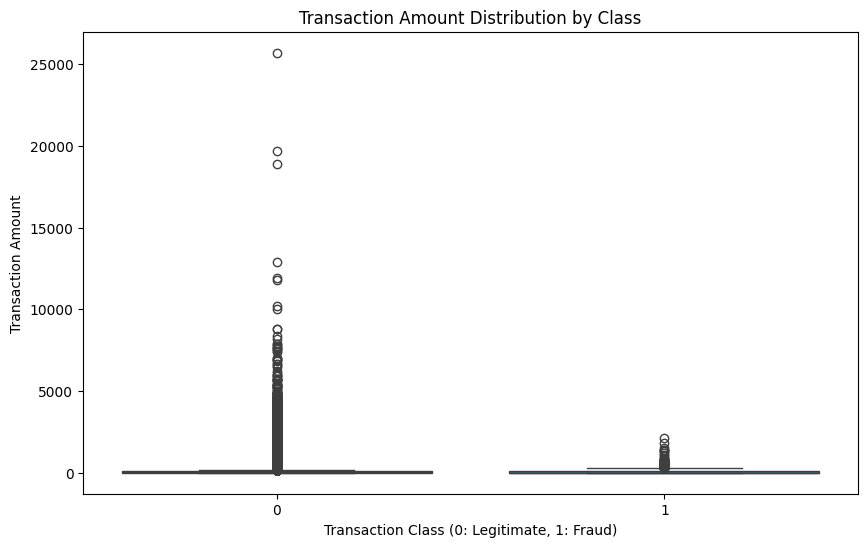

In [77]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Transaction Class (0: Legitimate, 1: Fraud)")
plt.ylabel("Transaction Amount")

plt.show()

**Feature Engineering**

Feature engineering is performed to create additional variables that may help the machine learning models capture transaction behavior.

Two important engineered features are created:

**1. Hour**

The original Time variable is transformed into an approximate hour-of-day representation.

This allows the analysis to investigate whether fraud frequency changes throughout the day.

**2. Log_Amount**

The transaction amount is transformed using:

Log_Amount = log1p(Amount)

This transformation reduces the effect of extreme transaction amounts and provides a more balanced representation of the highly skewed Amount variable.

Both original and transformed representations are retained because they may provide complementary information to the models.

In [78]:
df["Hour"] = ((df["Time"] // 3600) % 24).astype(int)

print("Hour feature created.")
print("Minimum hour:", df["Hour"].min())
print("Maximum hour:", df["Hour"].max())

Hour feature created.
Minimum hour: 0
Maximum hour: 23


In [79]:
fraud_by_hour = (
    df[df["Class"] == 1]
    .groupby("Hour")
    .size()
    .sort_index()
)

display(fraud_by_hour)

,0
Hour,
0,6
1,10
2,48
3,17
4,23
5,11
6,9
7,23
8,9


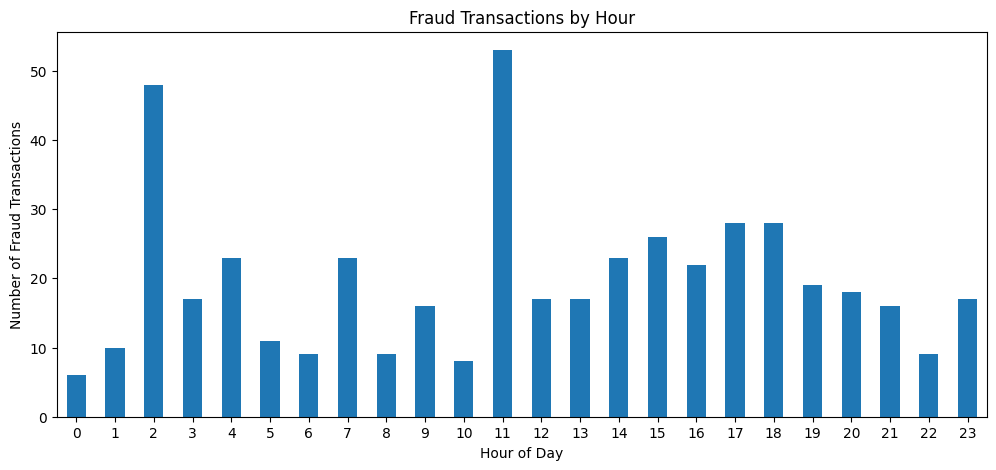

In [80]:

plt.figure(figsize=(12, 5))

fraud_by_hour.plot(kind="bar")

plt.title("Fraud Transactions by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Fraud Transactions")
plt.xticks(rotation=0)

plt.show()

In [81]:
#Creating Log_amount
df["Log_Amount"] = np.log1p(df["Amount"])

print(df[["Amount", "Log_Amount"]].describe())

              Amount     Log_Amount
count  283726.000000  283726.000000
mean       88.472687       3.153760
std       250.399437       1.657080
min         0.000000       0.000000
25%         5.600000       1.887070
50%        22.000000       3.135494
75%        77.510000       4.363226
max     25691.160000      10.153941


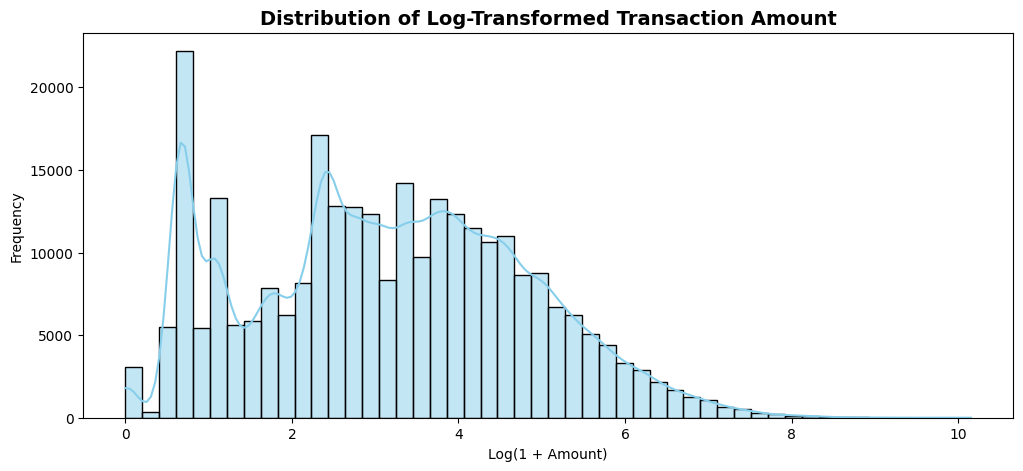

In [82]:
plt.figure(figsize=(12, 5))

# Using seaborn for a cleaner look with a distribution line
sns.histplot(data=df, x="Log_Amount", bins=50, kde=True, color="skyblue")

plt.title("Distribution of Log-Transformed Transaction Amount", fontsize=14, fontweight="bold")
plt.xlabel("Log(1 + Amount)")
plt.ylabel("Frequency")

plt.show()

In [83]:
display(df[["Amount", "Log_Amount"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
Amount,283726.0,88.472687,250.399437,0.0,5.60000,22.000000,77.510000,25691.160000
Log_Amount,283726.0,3.153760,1.657080,0.0,1.88707,3.135494,4.363226,10.153941


In [84]:
pca_features = [f"V{i}" for i in range(1, 29)]

display(df[pca_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
V1,283726.0,0.005917,1.948026,-56.407510,-0.915951,0.020384,1.316068,2.454930
V2,283726.0,-0.004135,1.646703,-72.715728,-0.600321,0.063949,0.800283,22.057729
V3,283726.0,0.001613,1.508682,-48.325589,-0.889682,0.179963,1.026960,9.382558
V4,283726.0,-0.002966,1.414184,-5.683171,-0.850134,-0.022248,0.739647,16.875344
V5,283726.0,0.001828,1.377008,-113.743307,-0.689830,-0.053468,0.612218,34.801666
V6,283726.0,-0.001139,1.331931,-26.160506,-0.769031,-0.275168,0.396792,73.301626
V7,283726.0,0.001801,1.227664,-43.557242,-0.552509,0.040859,0.570474,120.589494
V8,283726.0,-0.000854,1.179054,-73.216718,-0.208828,0.021898,0.325704,20.007208
V9,283726.0,-0.001596,1.095492,-13.434066,-0.644221,-0.052596,0.595977,15.594995
V10,283726.0,-0.001441,1.076407,-24.588262,-0.535578,-0.093237,0.453619,23.745136


In [85]:
print("Missing PCA values:", df[pca_features].isnull().sum().sum())

print("Infinite PCA values:",np.isinf(df[pca_features].to_numpy()).sum())

Missing PCA values: 0
Infinite PCA values: 0


In [86]:
correlations = (
    df.corr(numeric_only=True)["Class"]
    .drop("Class")
    .sort_values(key=abs, ascending=False)
)
display(correlations)

,Class
V17,-0.313498
V14,-0.293375
V12,-0.250711
V10,-0.206971
V16,-0.187186
V3,-0.182322
V7,-0.172347
V11,0.149067
V4,0.129326
V18,-0.105340


In [87]:
print("New features:")
print(["Hour", "Log_Amount"])

print("\nDataset shape:")
print(df.shape)

New features:
['Hour', 'Log_Amount']

Dataset shape:
(283726, 33)


In [88]:
# FRAUD PATTERN BY HOUR

hour_analysis = (
    df.groupby("Hour")["Class"].agg(Total_Transactions="count",Fraud_Count="sum"))

hour_analysis["Fraud_Rate_%"] = (hour_analysis["Fraud_Count"] /hour_analysis["Total_Transactions"] * 100)

display(hour_analysis)

,Total_Transactions,Fraud_Count,Fraud_Rate_%
Hour,,,
0,7647,6,0.078462
1,4208,10,0.237643
2,3308,48,1.451028
3,3487,17,0.487525
4,2204,23,1.043557
5,2988,11,0.368139
6,4082,9,0.220480
7,7233,23,0.317987
8,10232,9,0.087959


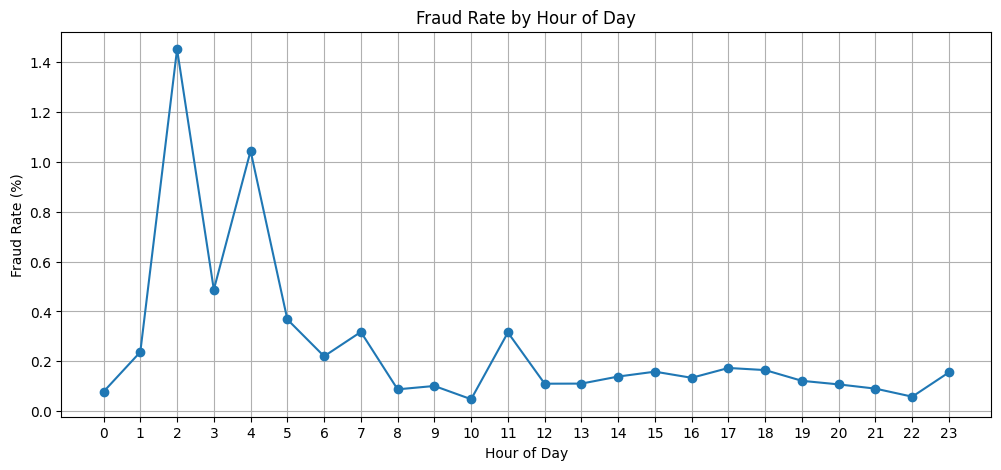

In [89]:
plt.figure(figsize=(12, 5))

plt.plot(
    hour_analysis.index,
    hour_analysis["Fraud_Rate_%"],
    marker="o"
)

plt.title("Fraud Rate by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(24))
plt.grid(True)

plt.show()

**Fraud Patterns by Time of Day**

Fraud transactions are analyzed by hour to identify potential temporal patterns.

Two measures are considered:

* Total number of fraudulent transactions by hour
* Fraud rate by hour

The fraud count indicates when the largest number of fraudulent transactions occurs, while the fraud rate provides a more meaningful comparison by considering the total number of transactions occurring during each hour.

In [90]:
print("Amount skewness:", df["Amount"].skew())
print("Log_Amount skewness:", df["Log_Amount"].skew())

Amount skewness: 16.978803370060476
Log_Amount skewness: 0.16141018223366638


In [91]:
print("Final rows:", df.shape[0])
print("Final columns:", df.shape[1])

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nInfinite values:")
print(np.isinf(df.select_dtypes(include=np.number)).sum().sum())

print("\nClass distribution:")
print(df["Class"].value_counts())

Final rows: 283726
Final columns: 33

Missing values:
0

Infinite values:
0

Class distribution:
Class
0    283253
1       473
Name: count, dtype: int64


In [92]:
# FINAL PREPROCESSING SUMMARY

summary = {
    "Original Rows": len(df_original),
    "Final Rows": len(df),
    "Rows Removed": len(df_original) - len(df),
    "Original Columns": df_original.shape[1],
    "Final Columns": df.shape[1],
    "Missing Values": df.isnull().sum().sum(),
    "Duplicate Rows Removed": df_original.duplicated().sum(),
    "Legitimate Transactions": (df["Class"] == 0).sum(),
    "Fraudulent Transactions": (df["Class"] == 1).sum()
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
)

display(summary_df)

,Metric,Value
0,Original Rows,284807
1,Final Rows,283726
2,Rows Removed,1081
3,Original Columns,31
4,Final Columns,33
5,Missing Values,0
6,Duplicate Rows Removed,1081
7,Legitimate Transactions,283253
8,Fraudulent Transactions,473


In [93]:
# Save cleaned dataset
output_path="creditcard_cleaned.csv"
df.to_csv(output_path, index=False)

In [94]:
# DEFINE FEATURES AND TARGET

# Target variable
y = df["Class"]

# Features
X = df.drop(columns=["Class"])

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nNon-numeric columns in X:")
print(X.select_dtypes(exclude="number").columns.tolist())

X shape: (283726, 32)
y shape: (283726,)

Non-numeric columns in X:
[]


In [95]:
# TRAIN / VALIDATION / TEST SPLIT

from sklearn.model_selection import train_test_split

# Drop any rows with missing values in our features or target first
df_clean = df.dropna().reset_index(drop=True)
y = df_clean["Class"]
X = df_clean.drop(columns=["Class"])

# First split: 80% development data, 20% final test data
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Second split: divide development data into 75% training and 25% validation
# Final proportions = 60% train, 20% validation, 20% test
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts())

print("\nValidation target:")
print(y_val.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

Training set: (170235, 32)
Validation set: (56745, 32)
Testing set: (56746, 32)

Training target:
Class
0    169951
1       284
Name: count, dtype: int64

Validation target:
Class
0    56651
1       94
Name: count, dtype: int64

Testing target:
Class
0    56651
1       95
Name: count, dtype: int64


In [96]:
# Find non-numeric columns in X_train

print("Non-numeric columns:")
print(X_train.select_dtypes(exclude="number").columns.tolist())

Non-numeric columns:
[]


**Train, Validation and Test Strategy**

The dataset is divided into three subsets:

* Training set: used to train the machine learning models.
* Validation set: used for model/threshold analysis and selection decisions.
* Test set: kept separate for final unbiased evaluation.

A stratified split is used so that the proportion of fraudulent and legitimate transactions remains consistent across the datasets.

The test set is not used during threshold selection. This prevents information from the final evaluation set from influencing model decisions.

In [97]:
#  FEATURE SCALING

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to validation and test data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Training data scaled successfully.")
print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training data scaled successfully.
Training shape: (170235, 32)
Validation shape: (56745, 32)
Testing shape: (56746, 32)


**Class Imbalance**

Credit card fraud detection is a highly imbalanced classification problem because legitimate transactions greatly outnumber fraudulent transactions.

This creates an important modeling challenge:

A model can achieve high overall accuracy while still failing to detect a meaningful number of fraudulent transactions.

Therefore, fraud detection performance is evaluated using metrics such as:

* Precision
* Recall
* F1-score
* ROC-AUC
* Precision-Recall analysis
* Confusion matrix

In [98]:
# CHECK CLASS IMBALANCE

print("Training class distribution:")
print(y_train.value_counts())

print("\nTraining class percentage:")
print(y_train.value_counts(normalize=True).mul(100).round(4))

Training class distribution:
Class
0    169951
1       284
Name: count, dtype: int64

Training class percentage:
Class
0    99.8332
1     0.1668
Name: proportion, dtype: float64


**Model 1 – Logistic Regression**

Logistic Regression is used as a baseline classification model.

It provides a relatively simple and interpretable benchmark against which more complex models can be compared.

The model uses class weighting to give additional importance to the minority fraud class.

The objective is to determine how well a linear classification approach can identify fraudulent transactions.

In [99]:
# LOGISTIC REGRESSION

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(class_weight="balanced",max_iter=1000,random_state=42)

logistic_model.fit(X_train_scaled,y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [100]:
# LOGISTIC REGRESSION PREDICTIONS

y_pred_logistic = logistic_model.predict(X_val_scaled)

y_prob_logistic = logistic_model.predict_proba(X_val_scaled)[:, 1]

print("Predictions completed.")

Predictions completed.


In [101]:
# EVALUATE LOGISTIC REGRESSION

from sklearn.metrics import *

accuracy_logistic = accuracy_score(y_val,y_pred_logistic)

precision_logistic = precision_score(y_val,y_pred_logistic)

recall_logistic = recall_score(y_val,y_pred_logistic)
f1_logistic = f1_score(y_val,y_pred_logistic)

roc_auc_logistic = roc_auc_score(y_val,y_prob_logistic)

pr_auc_logistic = average_precision_score(y_val,y_prob_logistic)

print("LOGISTIC REGRESSION")
print("----------------------------")
print("Accuracy :", round(accuracy_logistic, 4))
print("Precision:", round(precision_logistic, 4))
print("Recall   :", round(recall_logistic, 4))
print("F1 Score :", round(f1_logistic, 4))
print("ROC-AUC  :", round(roc_auc_logistic, 4))
print("PR-AUC   :", round(pr_auc_logistic, 4))
print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_pred_logistic
    )
)

LOGISTIC REGRESSION
----------------------------
Accuracy : 0.9746
Precision: 0.056
Recall   : 0.9043
F1 Score : 0.1055
ROC-AUC  : 0.9827
PR-AUC   : 0.7882

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.06      0.90      0.11        94

    accuracy                           0.97     56745
   macro avg       0.53      0.94      0.55     56745
weighted avg       1.00      0.97      0.99     56745



[[55219  1432]
 [    9    85]]


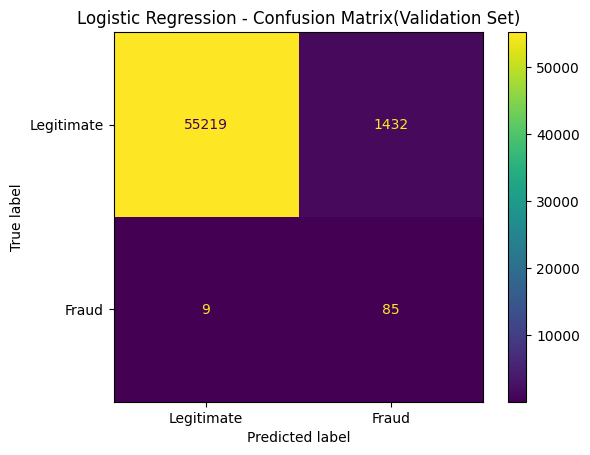

In [102]:
# LOGISTIC REGRESSION
# CONFUSION MATRIX

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_logistic = confusion_matrix(y_val,y_pred_logistic)

print(cm_logistic)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=["Legitimate", "Fraud"]
)

disp.plot()

plt.title("Logistic Regression - Confusion Matrix(Validation Set)")
plt.show()

**Model 2 – Random Forest**

Random Forest is introduced as a nonlinear ensemble learning method.

The model combines multiple decision trees and can capture complex relationships between transaction features.

Class weighting is used to give greater importance to the minority fraud class.

Random Forest is evaluated against the Logistic Regression approaches to determine whether a nonlinear model provides better fraud detection performance.

In [103]:
# RANDOM FOREST MODEL

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train,y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [104]:
# RANDOM FOREST PREDICTIONS

y_pred_rf = rf_model.predict(X_val)

y_prob_rf = rf_model.predict_proba(X_val)[:, 1]

print("Random Forest predictions completed.")

Random Forest predictions completed.


In [105]:
# EVALUATE RANDOM FOREST

accuracy_rf = accuracy_score(y_val,y_pred_rf)

precision_rf = precision_score(y_val,y_pred_rf)

recall_rf = recall_score(y_val,y_pred_rf)

f1_rf = f1_score(y_val,y_pred_rf)

roc_auc_rf = roc_auc_score(y_val,y_prob_rf)

pr_auc_rf = average_precision_score(y_val,y_prob_rf)

print("RANDOM FOREST")
print("----------------------------")
print("Accuracy :", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall   :", round(recall_rf, 4))
print("F1 Score :", round(f1_rf, 4))
print("ROC-AUC  :", round(roc_auc_rf, 4))
print("PR-AUC   :", round(pr_auc_rf, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_pred_rf
    )
)

RANDOM FOREST
----------------------------
Accuracy : 0.9996
Precision: 0.8876
Recall   : 0.8404
F1 Score : 0.8634
ROC-AUC  : 0.9598
PR-AUC   : 0.8557

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.89      0.84      0.86        94

    accuracy                           1.00     56745
   macro avg       0.94      0.92      0.93     56745
weighted avg       1.00      1.00      1.00     56745



Confusion Matrix:
[[56641    10]
 [   15    79]]


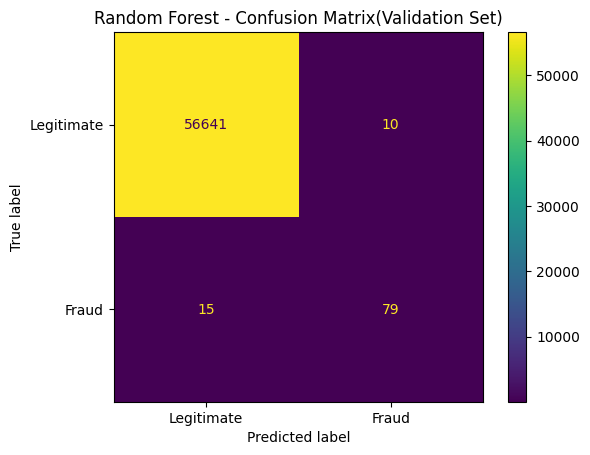

In [106]:
# RANDOM FOREST CONFUSION MATRIX

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_rf = confusion_matrix(y_val,y_pred_rf)

print("Confusion Matrix:")
print(cm_rf)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf,display_labels=["Legitimate", "Fraud"])

disp.plot()

plt.title("Random Forest - Confusion Matrix(Validation Set)")
plt.show()

**Model 3 – XGBoost**

XGBoost is a gradient boosting method that builds trees one after another, each correcting the errors of the previous ones.

Class imbalance is handled with scale_pos_weight.

XGBoost is compared with Logistic Regression and Random Forest to see whether a boosted model detects fraud better

In [107]:
# XGBOOST MODEL

from xgboost import XGBClassifier

# Ratio of legitimate to fraud cases in the training set (handles class imbalance)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(scale_pos_weight, 2))

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost training completed.")

scale_pos_weight: 598.42
XGBoost training completed.


In [108]:
# XGBOOST PREDICTIONS (on validation set)

y_pred_xgb = xgb_model.predict(X_val)
y_prob_xgb = xgb_model.predict_proba(X_val)[:, 1]

print("XGBoost predictions completed.")

XGBoost predictions completed.


In [109]:
# EVALUATE XGBOOST (on validation set)

accuracy_xgb = accuracy_score(y_val, y_pred_xgb)
precision_xgb = precision_score(y_val, y_pred_xgb)
recall_xgb = recall_score(y_val, y_pred_xgb)
f1_xgb = f1_score(y_val, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_val, y_prob_xgb)
pr_auc_xgb = average_precision_score(y_val, y_prob_xgb)

print("XGBOOST (validation)")
print("----------------------------")
print("Accuracy :", round(accuracy_xgb, 4))
print("Precision:", round(precision_xgb, 4))
print("Recall   :", round(recall_xgb, 4))
print("F1 Score :", round(f1_xgb, 4))
print("ROC-AUC  :", round(roc_auc_xgb, 4))
print("PR-AUC   :", round(pr_auc_xgb, 4))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_xgb))

XGBOOST (validation)
----------------------------
Accuracy : 0.9997
Precision: 0.9412
Recall   : 0.8511
F1 Score : 0.8939
ROC-AUC  : 0.9754
PR-AUC   : 0.885

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.94      0.85      0.89        94

    accuracy                           1.00     56745
   macro avg       0.97      0.93      0.95     56745
weighted avg       1.00      1.00      1.00     56745



Confusion Matrix (Validation Set):
[[56646     5]
 [   14    80]]


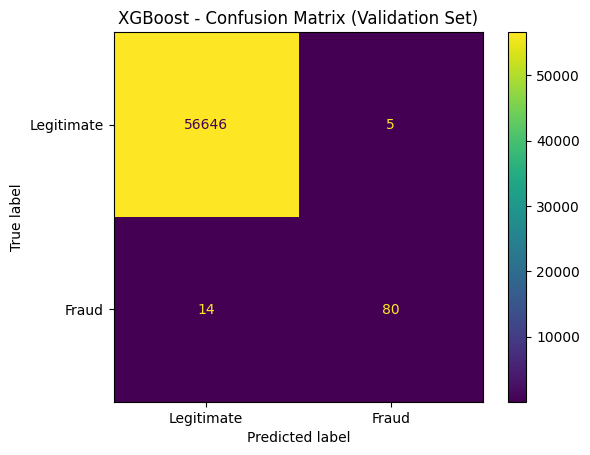

In [110]:
# STEP 17: XGBoost CONFUSION MATRIX

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Using y_val because y_pred_xgb contains predictions for the validation set
cm_xgb = confusion_matrix(y_val,y_pred_xgb)

print("Confusion Matrix (Validation Set):")
print(cm_xgb)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_xgb,display_labels=["Legitimate", "Fraud"])

disp.plot()

plt.title("XGBoost - Confusion Matrix (Validation Set)")
plt.show()

In [111]:
# FINAL MODEL COMPARISON TABLE

final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression - Balanced",
        "Random Forest - Balanced",
        "XGBoost - Balanced"
    ],
    "Accuracy": [
        accuracy_logistic,
        accuracy_rf,
        accuracy_xgb
    ],
    "Precision": [
        precision_logistic,
        precision_rf,
        precision_xgb
    ],
    "Recall": [
        recall_logistic,
        recall_rf,
        recall_xgb
    ],
    "F1 Score": [
        f1_logistic,
        f1_rf,
        f1_xgb
    ],
    "ROC-AUC": [
        roc_auc_logistic,
        roc_auc_rf,
        roc_auc_xgb
    ],
    "PR-AUC": [
        pr_auc_logistic,
        pr_auc_rf,
        pr_auc_xgb
    ]
})

display(final_results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression - Balanced,0.9746,0.0560,0.9043,0.1055,0.9827,0.7882
1,Random Forest - Balanced,0.9996,0.8876,0.8404,0.8634,0.9598,0.8557
2,XGBoost - Balanced,0.9997,0.9412,0.8511,0.8939,0.9754,0.8850


In [112]:
# KS AND GINI (validation set)

import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score

def ks_gini(y_true, y_prob):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    ks = np.max(tpr - fpr)
    gini = 2 * roc_auc_score(y_true, y_prob) - 1
    return ks, gini

ks_gini_results = []
for name, prob in [
    ("Logistic Regression - Balanced", y_prob_logistic),
    ("Random Forest - Balanced", y_prob_rf),
    ("XGBoost - Balanced", y_prob_xgb),
]:
    ks, gini = ks_gini(y_val, prob)
    ks_gini_results.append({"Model": name, "KS": ks, "Gini": gini})

display(pd.DataFrame(ks_gini_results).round(4))

,Model,KS,Gini
0,Logistic Regression - Balanced,0.8931,0.9654
1,Random Forest - Balanced,0.8919,0.9195
2,XGBoost - Balanced,0.9006,0.9508


KS measures how well a model separates fraudulent from legitimate transactions across all thresholds (higher is better, maximum 1). Gini is a rescaled ROC-AUC (2 × AUC − 1).

All three models separate fraud from legitimate transactions well (KS 0.89-0.90, Gini 0.92-0.97). KS is nearly identical across models, highest for XGBoost (0.901), while Logistic Regression has the highest Gini (0.965). KS and Gini are ROC-based and can look strong on rare-event data. Logistic Regression's precision is only 0.056, so model selection relies on PR-AUC and expected cost, where XGBoost performs best.

In [113]:
# FEATURE IMPORTANCE

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values("Importance",ascending=False)

display(feature_importance.head(15))

,Feature,Importance
14,V14,0.363371
10,V10,0.172834
4,V4,0.080971
12,V12,0.060693
8,V8,0.038734
19,V19,0.022722
17,V17,0.022433
3,V3,0.019922
29,Amount,0.019698
20,V20,0.017893


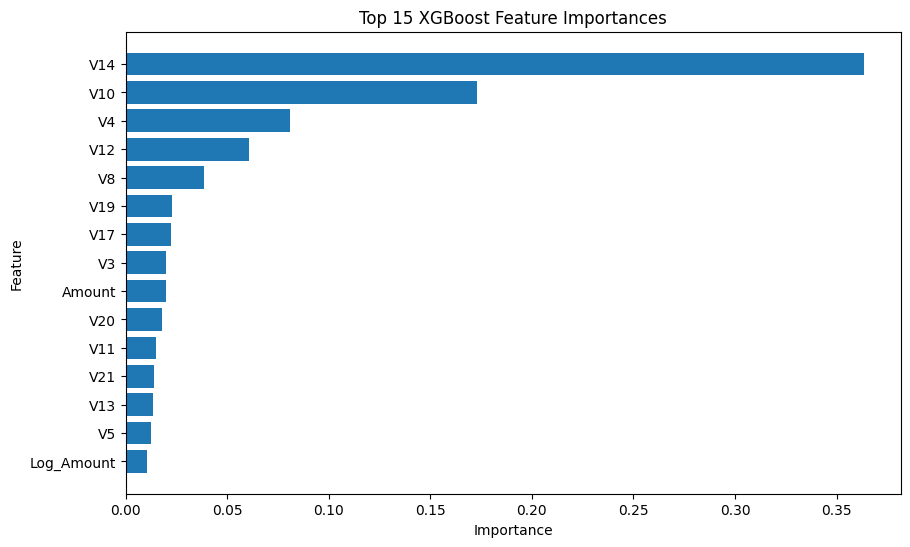

In [114]:
# TOP 15 FEATURE IMPORTANCES

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

plt.barh(top_features["Feature"][::-1],top_features["Importance"][::-1])

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 XGBoost Feature Importances")

plt.show()

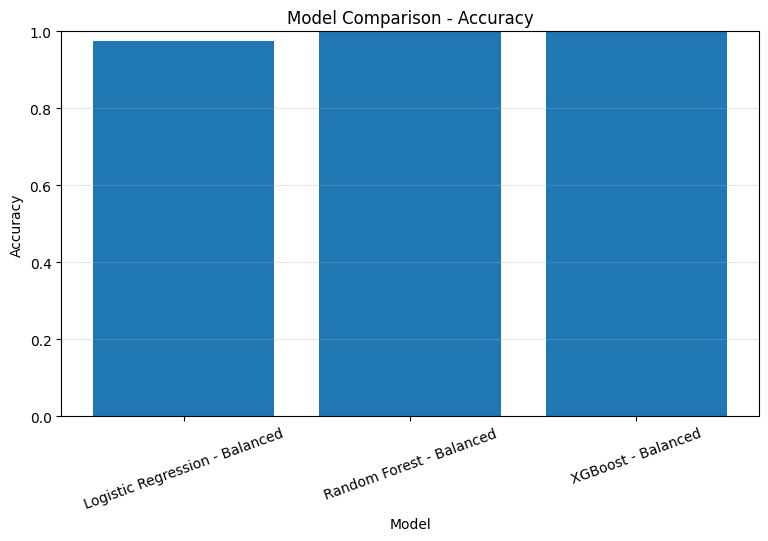

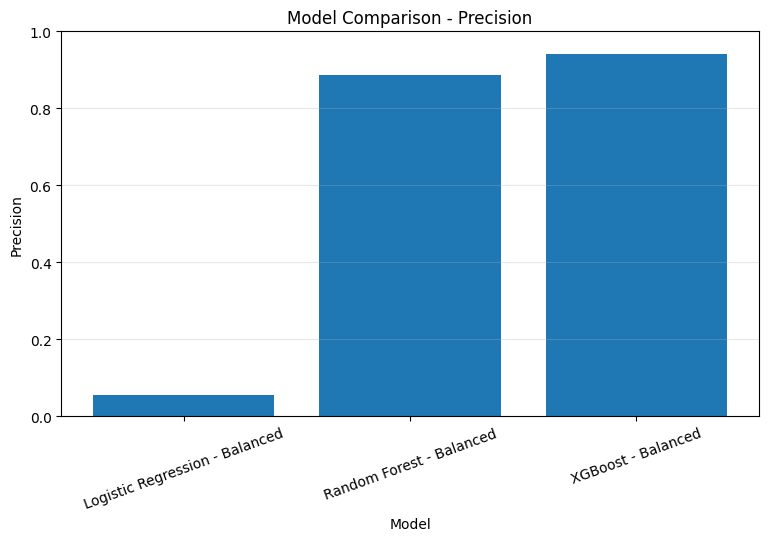

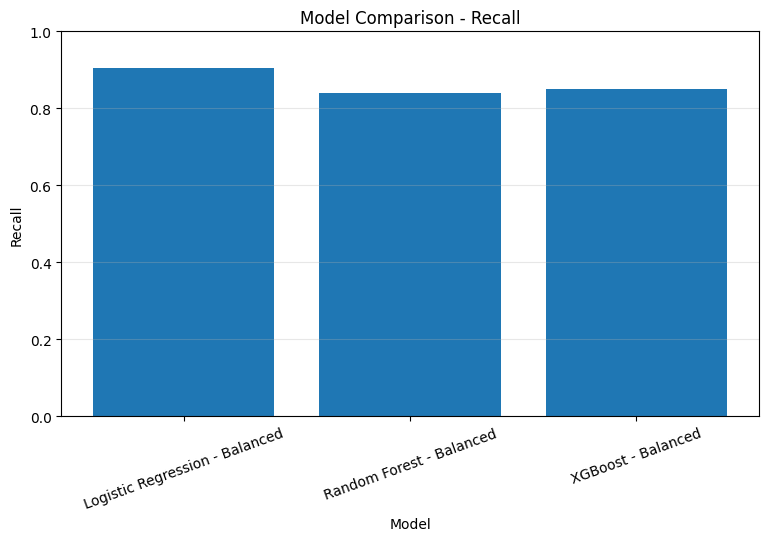

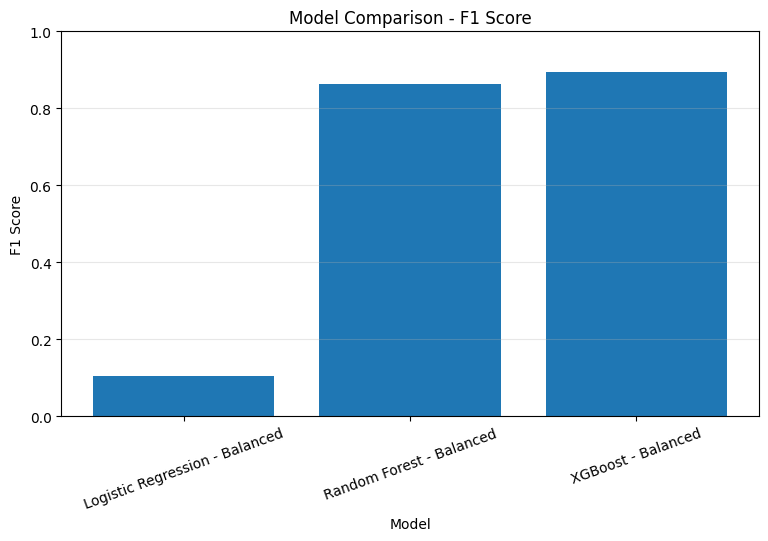

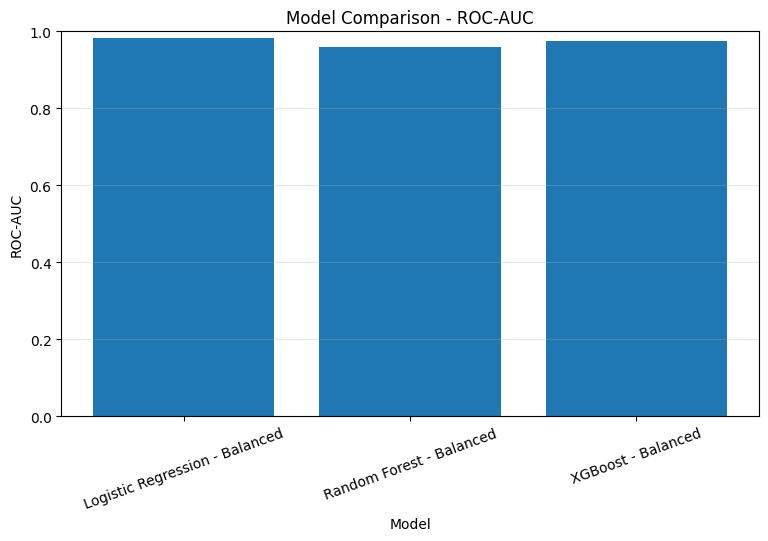

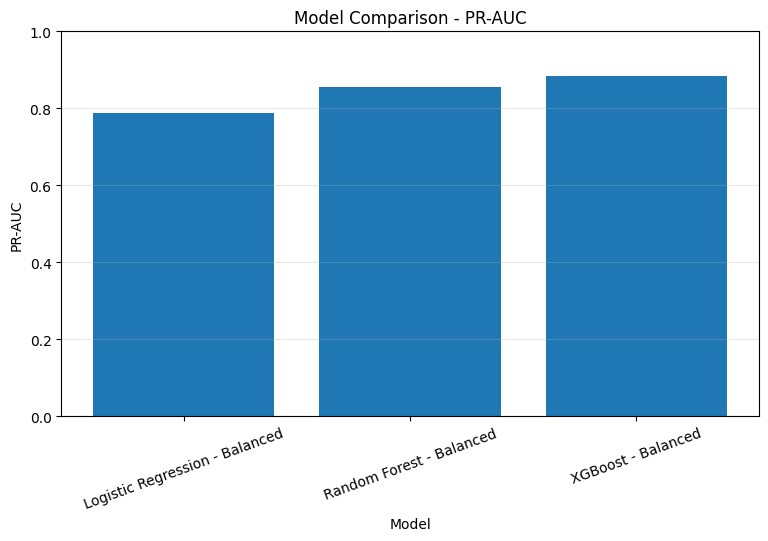

In [115]:
# MODEL PERFORMANCE COMPARISON

metrics = ["Accuracy","Precision","Recall","F1 Score","ROC-AUC","PR-AUC"]

for metric in metrics:

    plt.figure(figsize=(9, 5))

    plt.bar(final_results["Model"],final_results[metric])

    plt.ylabel(metric)
    plt.xlabel("Model")
    plt.title(f"Model Comparison - {metric}")

    plt.xticks(rotation=20)
    plt.ylim(0, 1)
    plt.grid(axis="y", alpha=0.3)

    plt.show()

In [116]:
# CONFUSION MATRIX COMPARISON

from sklearn.metrics import confusion_matrix

# Logistic Regression - Balanced
cm_logistic = confusion_matrix(y_val,y_pred_logistic)

# Random Forest
cm_rf = confusion_matrix(y_val,y_pred_rf)

# XGBoost
cm_xgb = confusion_matrix(y_val,y_pred_xgb)



print("Logistic Regression - Balanced")
print(cm_logistic)

print("\nRandom Forest - Balanced")
print(cm_rf)

print("XGBoost - Balanced")
print(cm_xgb)

Logistic Regression - Balanced
[[55219  1432]
 [    9    85]]

Random Forest - Balanced
[[56641    10]
 [   15    79]]
XGBoost - Balanced
[[56646     5]
 [   14    80]]


**ROC Curve Analysis**

The ROC curve evaluates model discrimination across different classification thresholds.

It compares:

* True Positive Rate
* False Positive Rate

ROC-AUC summarizes the model's ability to distinguish fraudulent transactions from legitimate transactions across thresholds.

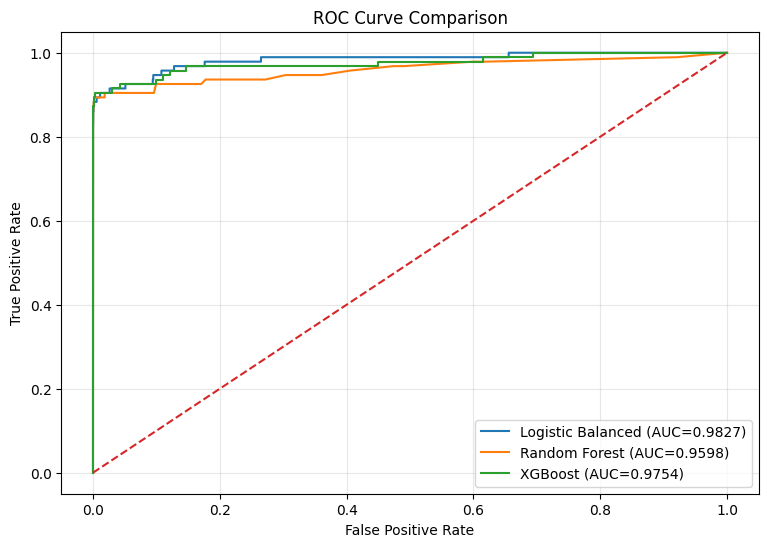

In [117]:
# ROC CURVE COMPARISON

from sklearn.metrics import roc_curve

fpr_logistic, tpr_logistic, _ = roc_curve(y_val,y_prob_logistic)

fpr_rf, tpr_rf, _ = roc_curve(y_val,y_prob_rf)

fpr_xgb, tpr_xgb, _ = roc_curve(y_val,y_prob_xgb)

plt.figure(figsize=(9, 6))
plt.plot(fpr_logistic,tpr_logistic,label=f"Logistic Balanced (AUC={roc_auc_logistic:.4f})")

plt.plot(fpr_rf,tpr_rf,label=f"Random Forest (AUC={roc_auc_rf:.4f})")
plt.plot(fpr_xgb,tpr_xgb,label=f"XGBoost (AUC={roc_auc_xgb:.4f})")

plt.plot([0, 1],[0, 1],linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

**Precision-Recall Analysis**

Precision-Recall analysis is particularly useful for highly imbalanced classification problems.

The curve illustrates the trade-off between:

* Precision
* Recall

As the classification threshold changes, the model may detect more fraudulent transactions but also generate more false positives.

Therefore, the Precision-Recall curve provides a useful view of the practical fraud detection trade-off.

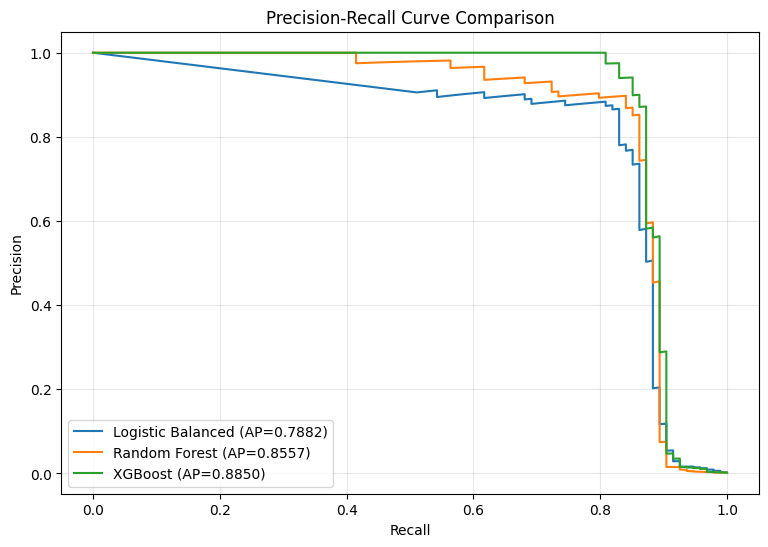

In [118]:
# PRECISION-RECALL CURVE COMPARISON

from sklearn.metrics import precision_recall_curve

precision_logistic_curve, recall_logistic_curve, _ = precision_recall_curve(y_val,y_prob_logistic)

precision_rf_curve, recall_rf_curve, _ = precision_recall_curve(y_val,y_prob_rf)

precision_xgb_curve, recall_xgb_curve, _ = precision_recall_curve(y_val,y_prob_xgb)

plt.figure(figsize=(9, 6))
plt.plot(recall_logistic_curve,precision_logistic_curve,label=f"Logistic Balanced (AP={pr_auc_logistic:.4f})")

plt.plot(recall_rf_curve,precision_rf_curve,label=f"Random Forest (AP={pr_auc_rf:.4f})")
plt.plot(recall_xgb_curve,precision_xgb_curve,label=f"XGBoost (AP={pr_auc_xgb:.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

**Feature Importance Analysis**

XGBoost feature importance is analyzed to identify which variables contribute most strongly to the model's predictions.

The most important features are examined to understand which transaction characteristics are most useful for distinguishing fraudulent and legitimate transactions.

This analysis supports both model interpretation and the final business story.

In [119]:
# TOP 20 IMPORTANT FEATURES

print("TOP 20 IMPORTANT FEATURES")
print("=" * 50)

display(feature_importance.head(20))

TOP 20 IMPORTANT FEATURES


,Feature,Importance
14,V14,0.363371
10,V10,0.172834
4,V4,0.080971
12,V12,0.060693
8,V8,0.038734
19,V19,0.022722
17,V17,0.022433
3,V3,0.019922
29,Amount,0.019698
20,V20,0.017893


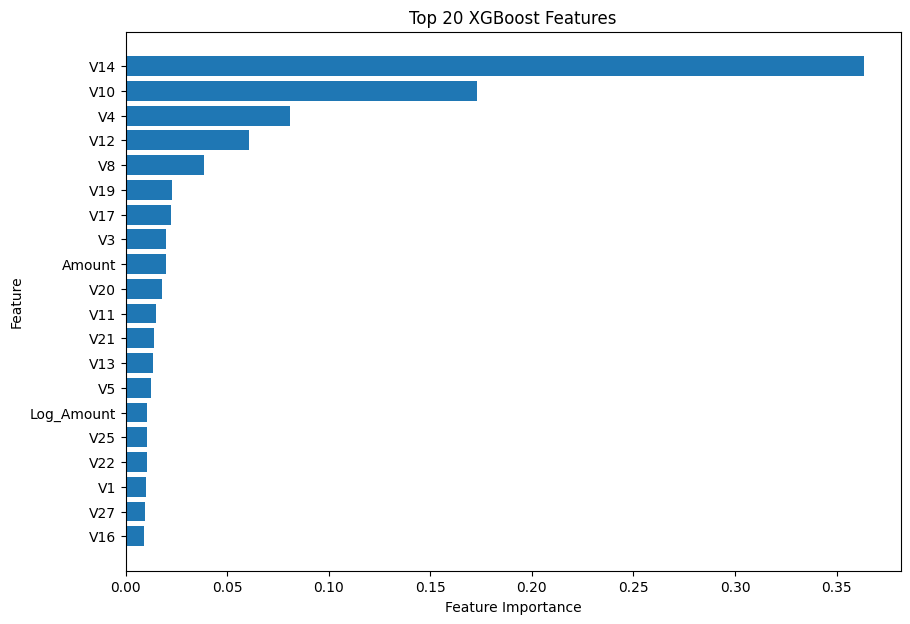

In [120]:
# TOP 20 FEATURE IMPORTANCE GRAPH

top_20 = feature_importance.head(20)

plt.figure(figsize=(10, 7))

plt.barh(top_20["Feature"][::-1],top_20["Importance"][::-1])

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 XGBoost Features")

plt.show()

**Threshold Optimization**

*Why Threshold Optimization?*

A binary classification model does not inherently have to use a probability threshold of exactly 0.50.

Changing the threshold changes the balance between:

* Fraud detection
* False alarms
* Precision
* Recall
* F1-score

For fraud detection, threshold selection is important because the cost of a missed fraudulent transaction may differ from the cost of investigating a legitimate transaction incorrectly flagged as fraud.

**Validation-Based Threshold Selection**

The XGBoost fraud probabilities are evaluated across multiple thresholds using the validation dataset.

Precision, recall and F1-score are calculated for each threshold.

The threshold with the best validation F1-score is identified as a reference point. The final threshold is chosen in the next section by minimizing expected cost.

The test dataset remains untouched during this selection process.

This approach avoids test-set leakage and provides a more reliable final performance estimate.

In [121]:
# THRESHOLD ANALYSIS

from sklearn.metrics import precision_score, recall_score, f1_score

# Get XGBoost probabilities on validation data
y_prob_xgb_val = xgb_model.predict_proba(X_val)[:, 1]

thresholds_to_test = [0.10,0.20,0.30,0.40,0.50,0.60,0.70,0.80,0.90,0.95,0.98,0.99,0.995]
threshold_results = []

for threshold in thresholds_to_test:

    y_threshold = (y_prob_xgb_val >= threshold).astype(int)

    threshold_results.append({"Threshold": threshold,
        "Precision": precision_score(y_val,y_threshold,zero_division=0),
        "Recall": recall_score(y_val,y_threshold,zero_division=0),
        "F1 Score": f1_score(y_val,y_threshold,zero_division=0)})

threshold_results = pd.DataFrame(threshold_results)

display(threshold_results.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.100,0.8632,0.8723,0.8677
1,0.200,0.8804,0.8617,0.8710
2,0.300,0.9195,0.8511,0.8840
3,0.400,0.9302,0.8511,0.8889
4,0.500,0.9412,0.8511,0.8939
5,0.600,0.9412,0.8511,0.8939
6,0.700,0.9412,0.8511,0.8939
7,0.800,0.9412,0.8511,0.8939
8,0.900,0.9405,0.8404,0.8876
9,0.950,0.9630,0.8298,0.8914


In [122]:
# SELECT BEST VALIDATION THRESHOLD

best_threshold_row = threshold_results.loc[threshold_results["F1 Score"].idxmax()]

best_threshold = best_threshold_row["Threshold"]

print("Best validation threshold:", best_threshold)
print("Validation F1 Score:",round(best_threshold_row["F1 Score"], 4))

Best validation threshold: 0.98
Validation F1 Score: 0.8966


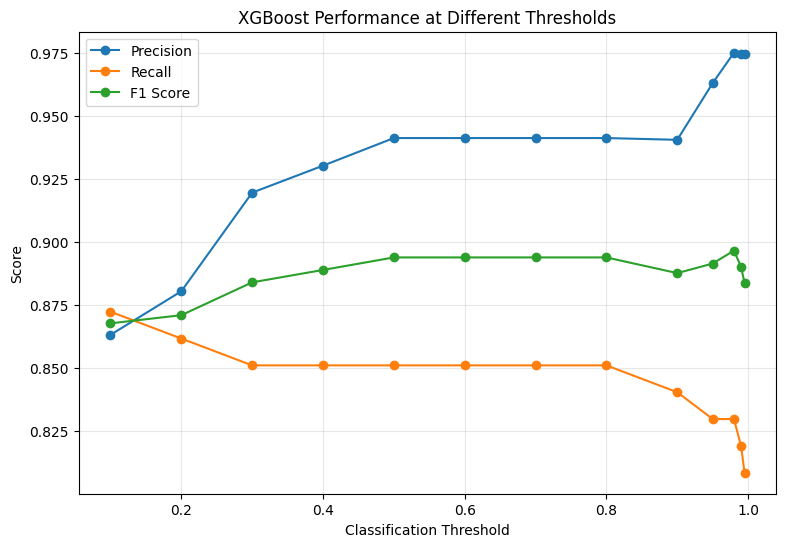

In [123]:
# THRESHOLD PERFORMANCE GRAPH

plt.figure(figsize=(9, 6))

plt.plot(threshold_results["Threshold"],threshold_results["Precision"],marker="o",label="Precision")

plt.plot(threshold_results["Threshold"],threshold_results["Recall"],marker="o",label="Recall")

plt.plot(threshold_results["Threshold"],threshold_results["F1 Score"],marker="o",label="F1 Score")

plt.xlabel("Classification Threshold")
plt.ylabel("Score")

plt.title("XGBoost Performance at Different Thresholds")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

Best cost-based threshold: 0.46


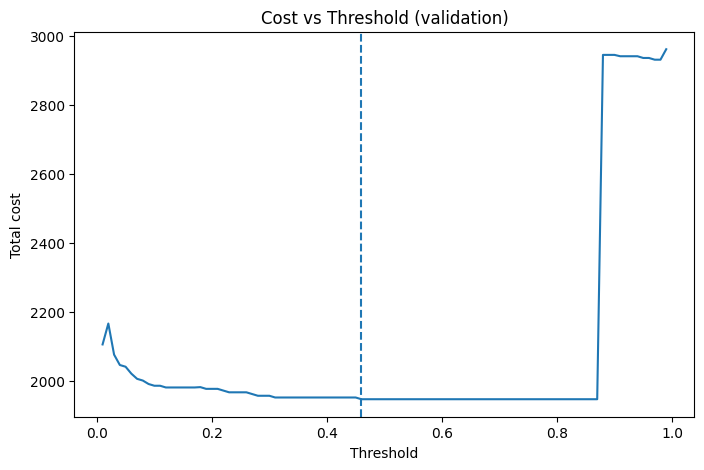

False-alert cost 1 -> best threshold 0.01
False-alert cost 5 -> best threshold 0.46
False-alert cost 20 -> best threshold 0.46
False-alert cost 50 -> best threshold 0.46


In [124]:
# COST-BASED THRESHOLD (selected on validation)
FALSE_ALERT_COST = 5   # assumption

amount_val = df_clean.loc[X_val.index, "Amount"].values
amount_test = df_clean.loc[X_test.index, "Amount"].values

def total_cost(y_true, prob, amount, thr, fa_cost):
    pred = (prob >= thr).astype(int)
    missed = (y_true.values == 1) & (pred == 0)
    false_alerts = (y_true.values == 0) & (pred == 1)
    return amount[missed].sum() + fa_cost * false_alerts.sum()

thresholds = np.arange(0.01, 1.0, 0.01)
costs = [total_cost(y_val, y_prob_xgb_val, amount_val, t, FALSE_ALERT_COST) for t in thresholds]
best_cost_threshold = thresholds[int(np.argmin(costs))]
print("Best cost-based threshold:", round(best_cost_threshold, 2))

plt.figure(figsize=(8, 5))
plt.plot(thresholds, costs)
plt.axvline(best_cost_threshold, linestyle="--")
plt.xlabel("Threshold"); plt.ylabel("Total cost")
plt.title("Cost vs Threshold (validation)")
plt.show()

# sensitivity to the assumed false-alert cost
for fa in [1, 5, 20, 50]:
    c = [total_cost(y_val, y_prob_xgb_val, amount_val, t, fa) for t in thresholds]
    print("False-alert cost", fa, "-> best threshold", round(thresholds[int(np.argmin(c))], 2))

**Final Test Evaluation**

After selecting the optimal classification threshold using the validation dataset, the selected threshold is applied to the previously untouched test dataset.

This provides the final estimate of model performance.

The final evaluation examines:

* Precision
* Recall
* F1-score
* Confusion matrix
* Fraud detection performance

The test set is used only at this final stage to avoid optimistic performance estimates.

In [125]:
y_prob_xgb_test = xgb_model.predict_proba(X_test)[:, 1]

rows = []
for name, thr in [("Default 0.5", 0.5), ("F1-optimal", best_threshold), ("Cost-based", best_cost_threshold)]:
    pred = (y_prob_xgb_test >= thr).astype(int)
    rows.append({
        "Rule": name, "Threshold": round(thr, 2),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Total cost": total_cost(y_test, y_prob_xgb_test, amount_test, thr, FALSE_ALERT_COST)
    })
rows.append({"Rule": "No model", "Threshold": None, "Precision": None, "Recall": 0,
             "F1": None, "Total cost": amount_test[y_test.values == 1].sum()})
display(pd.DataFrame(rows).round(4).fillna("--"))

print("Total fraud loss with no model:", round(amount_test[y_test.values == 1].sum(), 2))

,Rule,Threshold,Precision,Recall,F1,Total cost
0,Default 0.5,0.5,0.961,0.7789,0.8605,3807.56
1,F1-optimal,0.98,0.9857,0.7263,0.8364,4069.52
2,Cost-based,0.46,0.9487,0.7789,0.8555,3812.56
3,No model,--,--,0.0000,--,14766.31


Total fraud loss with no model: 14766.31


[[56647     4]
 [   21    74]]


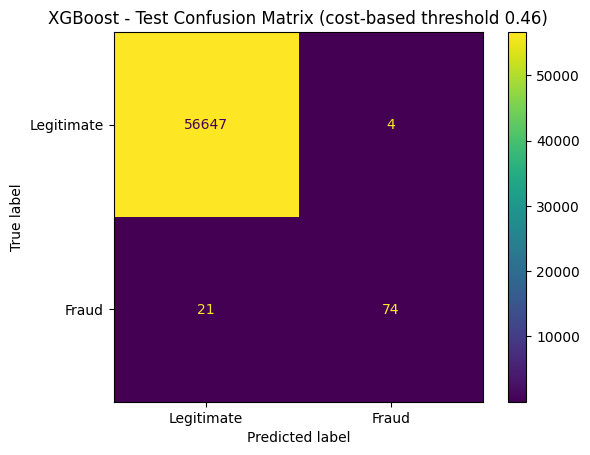

In [126]:
pred_final = (y_prob_xgb_test >= best_cost_threshold).astype(int)
cm_test = confusion_matrix(y_test, pred_final)
print(cm_test)

ConfusionMatrixDisplay(cm_test, display_labels=["Legitimate", "Fraud"]).plot()
plt.title("XGBoost - Test Confusion Matrix (cost-based threshold 0.46)")
plt.show()

In [127]:
# FINAL MODEL PERFORMANCE TABLE

print("FINAL MODEL PERFORMANCE(Validation set)")
print("=" * 70)

display( final_results.round(4))

FINAL MODEL PERFORMANCE(Validation set)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression - Balanced,0.9746,0.0560,0.9043,0.1055,0.9827,0.7882
1,Random Forest - Balanced,0.9996,0.8876,0.8404,0.8634,0.9598,0.8557
2,XGBoost - Balanced,0.9997,0.9412,0.8511,0.8939,0.9754,0.8850


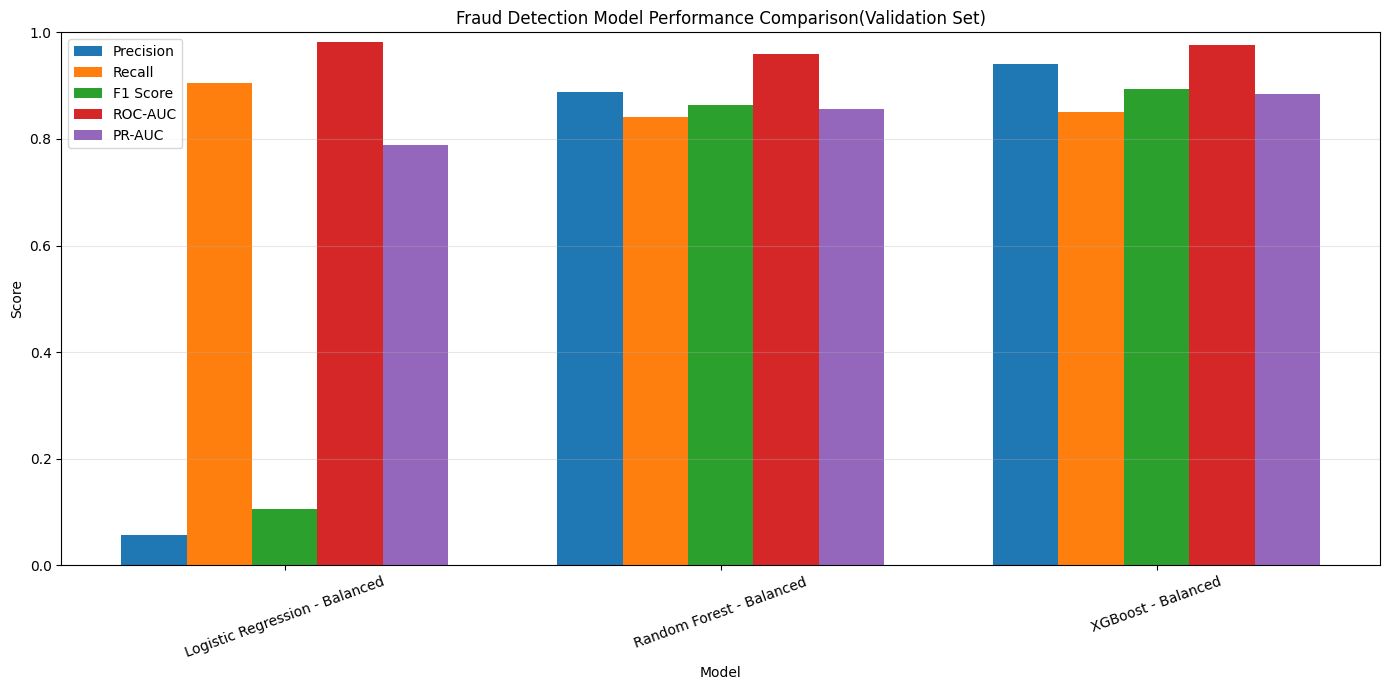

In [128]:
# MODEL PERFORMANCE COMPARISON (Validation Set)

metrics_to_plot = ["Precision","Recall","F1 Score","ROC-AUC","PR-AUC"]

model_names = final_results["Model"]

x = range(len(model_names))

width = 0.15

plt.figure(figsize=(14, 7))

for i, metric in enumerate(metrics_to_plot):

    values = final_results[metric]

    positions = [
        pos + (i - 2) * width
        for pos in x
    ]

    plt.bar(positions,values,width=width,label=metric)

plt.xticks(list(x),model_names,rotation=20)

plt.ylabel("Score")
plt.xlabel("Model")
plt.title("Fraud Detection Model Performance Comparison(Validation Set)")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Conclusion:** XGBoost with class weighting was the best model on validation (PR-AUC 0.885). On the test set, a cost-based threshold of 0.46 caught 78% of frauds at 95% precision and cut estimated fraud loss by about 74% versus no model. It matched the default 0.5 threshold and beat the F1-optimal threshold by about 6%, because F1 pushed the threshold too high and missed more fraud. Results are limited by the small number of fraud cases, the random split, and the assumed false-alert cost